In [4]:
%load_ext autoreload
%autoreload

import pandas as pd

import matplotlib.pyplot as plt

import sim_config as cfg
from sim_engine import run_replication
from sim_metrics import mm1_theory, stage_summary, compliance

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
df_manual = run_replication(cfg.SCENARIO_MANUAL)
df_digital = run_replication(cfg.SCENARIO_DIGITAL)
print(len(df_manual), len(df_digital))

1681 1681


In [6]:
stage_summary(df_manual, df_digital)

,stage,manual,digital,saved,reduction_pct
0,check_min,3.58,0.69,2.89,80.9
1,announcement_min,1.53,0.00,1.53,100.0
2,reg_wait_min,13.24,2.78,10.46,79.0
3,reg_service_min,4.84,2.90,1.94,40.0
4,walk_min,2.00,2.00,0.00,0.0
5,post_consult_min,15.00,15.00,0.00,0.0
6,total_opd_min,40.19,23.37,16.82,41.8


In [8]:
for sc, df in [(cfg.SCENARIO_MANUAL, df_manual), (cfg.SCENARIO_DIGITAL, df_digital)]:
    t = mm1_theory(cfg.REG_ARRIVAL_RATE_PER_MIN, sc.reg_service_mean_min)
print(f"{sc.name}: theory Wq={t['Wq']:.2f} min | simulated Wq={df['reg_wait_min'].mean():.2f} min | rho={t['rho']:.3f}")

digital: theory Wq=2.68 min | simulated Wq=2.78 min | rho=0.471


In [9]:
pd.DataFrame({"Manual": compliance(df_manual), "Digital": compliance(df_digital)})

,Manual,Digital
within_150_pct,100.0,100.0
within_180_pct,100.0,100.0
peak_within_150_pct,100.0,100.0
n_peak,1681.0,1681.0


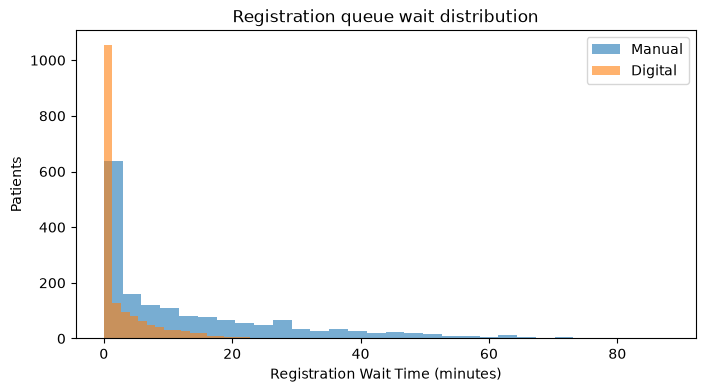

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for df, label in [(df_manual, "Manual"), (df_digital, "Digital")]:
    ax.hist(df["reg_wait_min"], bins=30, alpha=0.6, label=label)
ax.set_xlabel("Registration Wait Time (minutes)")
ax.set_ylabel("Patients")
ax.set_title("Registration queue wait distribution")
ax.legend()
plt.show()

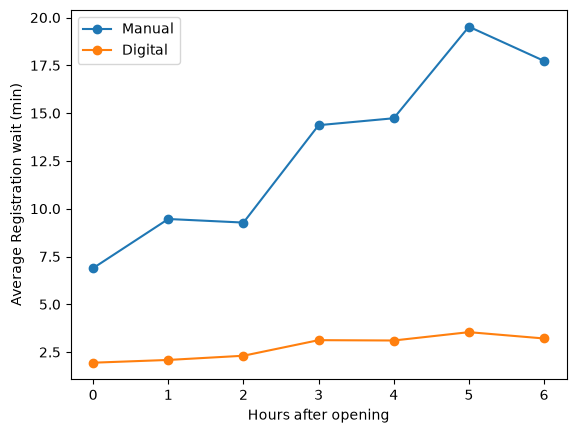

In [12]:
for df, label in [(df_manual, "Manual"), (df_digital, "Digital")]:
    df.groupby((df["arrival"] // 60).astype(int))["reg_wait_min"].mean().plot(marker="o", label=label)
plt.xlabel("Hours after opening")
plt.ylabel("Average Registration wait (min)")
plt.legend()
plt.show()